<a href="https://colab.research.google.com/github/jioh-shin/econ5200-final-project/blob/main/final_project_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECON 5200 Final Project: Consulting Report

**A causal question a client would pay to have answered, a design you can defend under attack, a tool that lets them
explore counterfactuals, and a recommendation with its uncertainty attached.**

This notebook is the spine of the project. Each milestone hands in part of it:

| Hand-in | Due | Parts |
|---|---|---|
| Milestone 1: Proposal + EDA (10 pts) | Mon 23 Nov | Part 2, plus the two-page proposal from the **Proposal Template (Word)** |
| Milestone 2: Analysis + Threats (20 pts) | Thu 3 Dec | Part 3, a first draft of Part 4, a Part 5 prototype with one working what-if input |
| Final Project (70 pts) | see Canvas | all of it, with Part 1 written last |

Every number in your report must be printed by a cell in this notebook. If the code does not print it, the report
cannot use it.

---

## Part 0: Setup

In [1]:
# Colab has pandas, numpy, statsmodels, scikit-learn and matplotlib already.
# Install only what your design needs, then restart the runtime once:
# !pip -q install linearmodels        # IV (2SLS) and panel fixed effects
# !pip -q install rdrobust rddensity   # RD
# !pip -q install doubleml             # DML

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

RANDOM_STATE = 42                    # every split, fold and bootstrap uses this seed
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (9, 5)
print("Setup complete.")

Setup complete.


---
## Part 1: Executive Summary

Write this **last**. Situation, Complication, Resolution, then the recommendation with its interval and the
assumption it rests on. The rubric looks for all three in the summary itself.

> **We estimate that [treatment] changes [outcome] by [X] [units] (95% CI [a, b]).**
>
> **Situation:** ___
> **Complication:** ___
> **Resolution:** ___
>
> **We recommend [action] because [reason]. At the bottom of the interval, [what the client should still do].**
>
> **The assumption that would overturn this:** ___

---
## Part 2: The Decision, the Design, and the Data (Milestone 1)

### Research design

These lines are the proposal's page 1. The **Proposal Template (Word)** on Canvas has the same headings.

- **Client and decision:** Young job seekers entering the labor market, as well as parents and career advisors who guide their decisions. This study will help them decide whether starting a career at a large establishment should be a priority when choosing a first full-time job.
- **Decides it:** If starting at a large establishment increases annual real earnings five years later by at least $3,000, job seekers may consider establishment size an important factor when choosing their first job. This proposed threshold is provisional because the preliminary data have already been examined.
- **Causal question:** Does starting an adult career at a large establishment increase annual earnings five years later?
- **Why prediction is not enough:** Workers at large establishments may have different abilities, education levels, and family backgrounds. A simple comparison of earnings may not show the actual effect of establishment size.
- **Design and estimand:** DML. The target is the a ATE among workers represented by the analytical sample.
- **Who is treated:** Individuals whose first observed adult full-time job was at an establishment with 500 or more employees. The preliminary sample contains 129 treated individuals.
- **The comparison:** 1,262 individuals whose first observed adult full-time job was at an establishment with fewer than 500 employees.
- **Key assumption:** Conditional independence and overlap. After controlling for relevant pre-employment characteristics, there should be no remaining confounding factors affecting both establishment size and future earnings.
- **How you will check it:** Examine the overlap of estimated propensity scores and differences in observed characteristics between the two groups.
- **The threat you worry about most:** Unobserved ability, education, and career motivation may increase both the probability of entering a large establishment and future earnings. This could lead to an upward bias in the estimated treatment effect.

In [17]:
from google.colab import files
import zipfile
import io

uploaded = files.upload()

Saving nlsy97_career_data.zip to nlsy97_career_data.zip


In [18]:
with zipfile.ZipFile(io.BytesIO(uploaded["nlsy97_career_data.zip"])) as z: z.extractall("data")

raw = pd.read_csv("data/nlsy97_career_data.csv")

print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (8984, 1886)


,R0000100,R0240800,R0240900,R0241000,R0241100,R0241200,R0241300,R0241400,R0241500,R0241600,...,U7365500,U7365600,U7365700,U7365800,U7365900,U7366000,U7366100,U7366200,U7366300,U7366400
0,1,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,200702,-4,-4,-4,-4,-4,-4,-4,-4,-4
1,2,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,200802,-4,-4,-4,-4,-4,-4,-4,-4,-4
2,3,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
3,4,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,202302,201901,-4,-4,-4,-4,-4,-4,-4,-4
4,5,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,200602,202102,-4,-4,-4,-4,-4,-4,-4,-4


In [19]:
import re
from pathlib import Path

codebook = Path("data/nlsy97_career_data.cdb").read_text(encoding="latin-1")

pattern = r"^([A-Z]\d{5}\.\d{2})\s+\[([^\]]+)\]\s+Survey Year:\s*(\d{4})"

matches = re.findall(pattern, codebook, re.MULTILINE)

metadata = pd.DataFrame(matches, columns=["reference", "variable", "year"])

metadata["reference"] = metadata["reference"].str.replace(".", "", regex=False)

metadata["year"] = metadata["year"].astype(int)

print("Variables identified:", len(metadata))
metadata.head(10)

Variables identified: 1885


,reference,variable,year
0,R0000100,PUBID,1997
1,R0240800,YEMP-100600.01,1997
2,R0240900,YEMP-100600.02,1997
3,R0241000,YEMP-100600.03,1997
4,R0241100,YEMP-100600.04,1997
5,R0241200,YEMP-100600.05,1997
6,R0241300,YEMP-100600.06,1997
7,R0241400,YEMP-100600.07,1997
8,R0241500,YEMP-100700.01,1997
9,R0241600,YEMP-100700.02,1997


In [20]:
metadata["category"] = metadata["variable"].str.split(".").str[0]

metadata["category"].value_counts().head(30)

,count
category,
YEMP_STARTDATE,250
YEMP_STOPDATE,250
YEMP_UID,203
CV_HRS_PER_WEEK,203
CV_HRLY_PAY,203
YEMP-100700,192
YEMP-100600,192
YEMP-101000,172
YEMP-100800,126


In [21]:
metadata["category"] = metadata["variable"].str.split(".").str[0]

metadata["category"].value_counts()

,count
category,
YEMP_STARTDATE,250
YEMP_STOPDATE,250
YEMP_UID,203
CV_HRS_PER_WEEK,203
CV_HRLY_PAY,203
YEMP-100700,192
YEMP-100600,192
YEMP-101000,172
YEMP-100800,126


In [22]:
missing = set(raw.columns) - set(metadata["reference"])

print("Unmatched variables:", missing)

Unmatched variables: {'R9829600'}


In [23]:
keywords = "START|STOP|UID|HRS|PAY|YINC|HGC|DEGREE|ASVAB|KEY"

important = metadata[metadata["variable"].str.contains(keywords, case=False, regex=True)]

important.groupby("category").agg(count=("reference", "count"), first_year=("year", "min"), last_year=("year", "max"))

,count,first_year,last_year
category,,,
CV_HGC_BIO_DAD,1,1997,1997
CV_HGC_BIO_MOM,1,1997,1997
CV_HGC_EVER_EDT,8,2010,2023
CV_HIGHEST_DEGREE_EVER_EDT,8,2010,2023
CV_HRLY_PAY,203,1997,2023
CV_HRS_PER_WEEK,203,1997,2023
KEY!BDATE_M,1,1997,1997
KEY!BDATE_Y,1,1997,1997
KEY!RACE_ETHNICITY,1,1997,1997


In [24]:
metadata.loc[len(metadata)] = ["R9829600", "ASVAB_MATH_VERBAL_SCORE_PCT", "XRND", "ASVAB_MATH_VERBAL_SCORE_PCT"]

print("Matched variables:", len(metadata))
print("Unmatched:", set(raw.columns) - set(metadata["reference"]))

Matched variables: 1886
Unmatched: set()


In [4]:
# --- Missing values and the sample rule ---
# print(df.isna().sum().sort_values(ascending=False).head(10))
# Write down every row you drop and why: the report's sample rule comes from this cell.

In [25]:
# Replace missing-value codes with NaN
df = raw.replace([-1, -2, -3, -4, -5], np.nan)

print("Original sample:", len(raw))
print("Unique individuals:", df["R0000100"].nunique())
print("Valid ASVAB scores:", df["R9829600"].notna().sum())

Original sample: 8984
Unique individuals: 8984
Valid ASVAB scores: 7093


In [26]:
job_vars = metadata[metadata["category"].isin(["YEMP_STARTDATE", "YEMP_UID", "YEMP-100700", "CV_HRS_PER_WEEK", "CV_HRLY_PAY"])]

display(pd.crosstab(job_vars["year"], job_vars["category"]))

category,CV_HRLY_PAY,CV_HRS_PER_WEEK,YEMP-100700,YEMP_STARTDATE,YEMP_UID
year,,,,,
1997,7,7,7,14,7
1998,9,9,8,18,9
1999,9,9,8,18,9
2000,9,9,9,18,9
2001,8,8,7,16,8
2002,11,11,10,22,11
2003,10,10,10,20,10
2004,7,7,7,14,7
2005,9,9,9,18,9


In [27]:
# Construct job-level data

job_data = []

for year in range(1997, 2011):

    m = metadata[metadata["year"] == year]

    lookup = dict(zip(m["variable"], m["reference"]))

    for j in range(1, 20):

        suffix = f"{j:02d}"

        names = {"job_id": f"YEMP_UID.{suffix}", "employees": f"YEMP-100700.{suffix}", "hours": f"CV_HRS_PER_WEEK.{suffix}", "hourly_pay": f"CV_HRLY_PAY.{suffix}"}

        start_name = f"YEMP_STARTDATE.{suffix}~Y"

        if start_name not in lookup:
            start_name = f"YEMP_STARTDATE.{suffix}_Y"

        if start_name not in lookup:
            continue

        temp = pd.DataFrame({"id": df["R0000100"], "survey_year": year, "start_year": df[lookup[start_name]]})

        for col, name in names.items():
            temp[col] = (df[lookup[name]]if name in lookup else np.nan)

        job_data.append(temp)

jobs = pd.concat(job_data, ignore_index=True)

jobs = jobs.dropna(subset=["job_id", "start_year"])

print("Job records:", len(jobs))
print("Individuals:", jobs["id"].nunique())

jobs.head(10)

Job records: 143756
Individuals: 8810


,id,survey_year,start_year,job_id,employees,hours,hourly_pay
0,1,1997,1997.0,9701.0,NaN,28.0,430.0
7,8,1997,1997.0,9701.0,4.0,14.0,515.0
29,30,1997,1996.0,9701.0,NaN,12.0,300.0
31,32,1997,1994.0,9701.0,NaN,12.0,475.0
32,33,1997,1996.0,9701.0,NaN,5.0,500.0
35,36,1997,1996.0,9703.0,40.0,20.0,475.0
58,59,1997,1996.0,9701.0,NaN,15.0,62.0
65,66,1997,1994.0,9701.0,NaN,0.0,NaN
67,68,1997,1996.0,9701.0,600.0,3.0,3333.0
70,71,1997,1995.0,9701.0,NaN,20.0,495.0


In [28]:
# Clean establishment size and hourly pay

jobs["employees"] = jobs["employees"].where(jobs["employees"].between(1, 99994))

jobs["hourly_pay"] = jobs["hourly_pay"] / 100

print("Valid establishment size:",
      jobs["employees"].notna().sum())

print("Valid working hours:",
      jobs["hours"].notna().sum())

print("Full-time job records:",
      (jobs["hours"] >= 35).sum())

jobs.describe()

Valid establishment size: 84334
Valid working hours: 140233
Full-time job records: 69854


,id,survey_year,start_year,job_id,employees,hours,hourly_pay
count,143756.000000,143756.000000,143756.000000,143756.000000,84334.000000,140233.000000,138256.000000
mean,4468.915183,2003.867832,2002.714746,177387.521620,247.491202,29.990338,10.943023
std,2554.929676,3.659025,3.532054,62025.505542,1700.800405,14.525956,36.287910
min,1.000000,1997.000000,1900.000000,9701.000000,1.000000,0.000000,0.000000
25%,2295.000000,2001.000000,2000.000000,200002.000000,10.000000,20.000000,6.000000
50%,4438.000000,2004.000000,2003.000000,200203.000000,25.000000,34.000000,8.000000
75%,6576.000000,2007.000000,2005.000000,200503.000000,100.000000,40.000000,11.500000
max,9022.000000,2010.000000,2011.000000,201010.000000,90000.000000,168.000000,6000.000000


In [29]:
# Construct job records including start month

parts = []

for year in range(1997, 2011):

    m = metadata[metadata["year"] == year]
    lookup = dict(zip(m["variable"], m["reference"]))

    def get(*names):
        for name in names:
            if name in lookup:
                return df[lookup[name]]
        return pd.Series(np.nan, index=df.index)

    for j in range(1, 20):

        k = f"{j:02d}"

        if f"YEMP_UID.{k}" not in lookup:
            continue

        parts.append(pd.DataFrame({"id": df["R0000100"], "survey_year": year, "job_id": get(f"YEMP_UID.{k}"), "start_year": get(f"YEMP_STARTDATE.{k}~Y", f"YEMP_STARTDATE.{k}_Y"), "start_month": get( f"YEMP_STARTDATE.{k}~M", f"YEMP_STARTDATE.{k}_M"), "employees": get(f"YEMP-100700.{k}"), "hours": get(f"CV_HRS_PER_WEEK.{k}")}))

job_records = pd.concat(parts, ignore_index=True)

job_records = job_records.dropna(subset=["job_id", "start_year", "start_month"])

In [30]:
# Add birth information

birth = df[["R0000100", "R0536401", "R0536402"]].rename(columns={"R0000100": "id", "R0536401": "birth_month", "R0536402": "birth_year"})

job_records = job_records.merge(birth, on="id")

job_records["age_months"] = (12 * (job_records["start_year"] - job_records["birth_year"]) + job_records["start_month"] - job_records["birth_month"])

# Restrict to adult full-time job records

adult_jobs = job_records[job_records["start_month"].between(1, 12) & job_records["start_year"].between(1997, 2010) & (job_records["age_months"] >= 216) & (job_records["start_year"]
       <= job_records["survey_year"] + 1) & job_records["hours"].between(35, 168)].copy()

# Remove repeated records of the same job

adult_jobs = adult_jobs.sort_values(["id", "job_id", "survey_year"]).drop_duplicates(["id", "job_id"])

adult_jobs["start_date"] = (adult_jobs["start_year"] * 12 + adult_jobs["start_month"])

# Identify the earliest observed eligible job

first_jobs = adult_jobs[adult_jobs["start_date"].eq(adult_jobs.groupby("id")["start_date"].transform("min"))].copy()

# Exclude ambiguous first jobs

first_jobs = first_jobs[~first_jobs["id"].duplicated(keep=False)]

print("Individuals:", len(first_jobs))

Individuals: 8026


In [31]:
# Restrict entry cohorts

first_jobs = first_jobs[first_jobs["start_year"].between(1999, 2005) & (first_jobs["survey_year"] <= first_jobs["start_year"] + 1)].copy()

print("Eligible entry cohorts:", len(first_jobs))

# Keep observations with valid establishment size

first_jobs = first_jobs[first_jobs["employees"].between(1, 99994)].copy()

first_jobs["large"] = (first_jobs["employees"] >= 500).astype(int)

print("Sample with valid size:", len(first_jobs))
print(first_jobs["large"].value_counts())

Eligible entry cohorts: 6316
Sample with valid size: 3161
large
0    2893
1     268
Name: count, dtype: int64


In [32]:
# Link annual earnings five years after entry

income_vars = metadata[metadata["variable"] == "YINC-1700"]

income_parts = []

for _, row in income_vars.iterrows():

    income_parts.append(pd.DataFrame({"id": df["R0000100"], "income_year": int(row["year"]) - 1, "annual_earnings": df[row["reference"]]}))

income_data = pd.concat(income_parts, ignore_index=True)

first_jobs["income_year"] = (first_jobs["start_year"] + 5).astype(int)

analysis = first_jobs.merge(income_data, on=["id", "income_year"], how="left")

print("Before income restriction:", len(analysis))

analysis = analysis[analysis["annual_earnings"].ge(0)].copy()

print("After income restriction:", len(analysis))
print(analysis["large"].value_counts())

analysis.head()

Before income restriction: 3161
After income restriction: 2078
large
0    1883
1     195
Name: count, dtype: int64


,id,survey_year,job_id,start_year,start_month,employees,hours,birth_month,birth_year,age_months,start_date,large,income_year,annual_earnings
0,1,2004,200103.0,2003.0,2.0,2.0,50.0,9,1981,257.0,24038.0,0,2008,43500.0
2,5,2004,200402.0,2004.0,8.0,18.0,40.0,10,1982,262.0,24056.0,0,2009,62000.0
4,8,2003,200302.0,2003.0,10.0,3.0,40.0,6,1981,268.0,24046.0,0,2008,15000.0
8,23,2005,200502.0,2005.0,2.0,150.0,35.0,1,1983,265.0,24062.0,0,2010,56813.0
9,27,2001,200001.0,2001.0,9.0,30.0,40.0,5,1981,244.0,24021.0,0,2006,3000.0


In [33]:
# Add individual background characteristics

controls = {"KEY!SEX": "gender", "KEY!RACE_ETHNICITY": "race", "CV_HGC_BIO_MOM": "mother_education", "CV_HGC_BIO_DAD": "father_education"}

background = pd.DataFrame({"id": df["R0000100"], "asvab": df["R9829600"]})

for variable, name in controls.items():

    ref = metadata.loc[metadata["variable"] == variable, "reference"].iloc[0]

    background[name] = df[ref]

analysis = analysis.merge(background, on="id")

analysis["entry_age"] = (analysis["age_months"] / 12)

print("Sample size:", len(analysis))

analysis[["annual_earnings", "entry_age", "asvab", "mother_education", "father_education"]].describe()

Sample size: 2078


,annual_earnings,entry_age,asvab,mother_education,father_education
count,2078.00000,2078.000000,1710.000000,1943.000000,1704.000000
mean,27114.50000,19.590512,47311.922807,12.546577,12.480047
std,18922.32558,1.417345,28051.172318,4.330783,3.198770
min,0.00000,18.000000,0.000000,1.000000,2.000000
25%,15000.00000,18.500000,22897.500000,12.000000,12.000000
50%,25000.00000,19.166667,46293.000000,12.000000,12.000000
75%,35000.00000,20.250000,70799.500000,14.000000,14.000000
max,146002.00000,25.250000,100000.000000,95.000000,20.000000


In [34]:
# Clean background variables

for col in ["mother_education", "father_education"]: analysis[col] = analysis[col].where(analysis[col].between(0, 20))

analysis["asvab_pct"] = analysis["asvab"] / 1000

analysis["female"] = (analysis["gender"] == 2).astype(int)

In [35]:
# Convert nominal earnings to 2010 dollars
# Source: BLS annual average CPI-U

cpi = {2004: 188.9, 2005: 195.3, 2006: 201.6, 2007: 207.342, 2008: 215.303, 2009: 214.537, 2010: 218.056}

analysis["cpi"] = analysis["income_year"].map(cpi)

analysis["real_earnings"] = (analysis["annual_earnings"] * cpi[2010] / analysis["cpi"])

analysis["real_earnings"].describe()

,real_earnings
count,2078.000000
mean,28803.027528
std,19830.332920
min,0.000000
25%,15775.096218
50%,26426.471891
75%,37379.504239
max,146002.000000


In [36]:
# Check missing values in analysis variables

control_cols = ["female", "race", "entry_age", "asvab_pct", "mother_education", "father_education", "start_year"]

print("Missing values:")
print(analysis[control_cols].isna().sum())

# Complete-case preliminary sample

final = analysis.dropna(subset=control_cols + ["real_earnings"]).copy()

print("\nBefore dropping missing controls:", len(analysis))
print("Final preliminary sample:", len(final))
print("Excluded:", len(analysis) - len(final))

print("\nTreatment and control:")
print(final["large"].value_counts())

Missing values:
female                0
race                  0
entry_age             0
asvab_pct           368
mother_education    138
father_education    374
start_year            0
dtype: int64

Before dropping missing controls: 2078
Final preliminary sample: 1391
Excluded: 687

Treatment and control:
large
0    1262
1     129
Name: count, dtype: int64


In [37]:
def balance_table(data, group, cols):
    """Means by group, the difference, and the standardised difference (difference / pooled SD).

    group: a 0/1 column. For RD pass the rows inside your bandwidth, grouped by side of the cutoff;
    for DiD, the pre-period rows grouped by treated state; for IV, grouped by the instrument.
    A standardised difference above about 0.1 in absolute value is worth a sentence in the proposal.
    """
    g1, g0 = data[data[group] == 1], data[data[group] == 0]
    rows = []
    for c in cols:
        sd = np.sqrt((g1[c].var() + g0[c].var()) / 2)
        rows.append({"variable": c, "treated": g1[c].mean(), "comparison": g0[c].mean(),
                     "difference": g1[c].mean() - g0[c].mean(),
                     "std. difference": (g1[c].mean() - g0[c].mean()) / sd if sd > 0 else np.nan})
    out = pd.DataFrame(rows).set_index("variable")
    out.loc["N"] = [len(g1), len(g0), np.nan, np.nan]
    return out.round(3)


# balance_table(df, "treated", ["outcome", "control_1", "control_2"])

In [6]:
# --- Figure 1: the relationship your design is built on ---
# DiD: mean outcome by period for each group, a vertical line at the treatment date
#   df.groupby(["period", "treated"])["outcome"].mean().unstack().plot(marker="o")
# RD: binned means of the outcome against the running variable, a vertical line at the cutoff
#   bins = pd.cut(df["running"], 40); df.groupby(bins, observed=True)["outcome"].mean().plot(style="o")
# IV: the first stage, treatment rate by value of the instrument
#   df.groupby("instrument")["treatment"].mean().plot(kind="bar")
# plt.title("..."); plt.xlabel("..."); plt.ylabel("..."); plt.show()

In [38]:
table1 = balance_table(final, "large", ["real_earnings", "entry_age", "asvab_pct", "female", "mother_education", "father_education"])

display(table1)

,treated,comparison,difference,std. difference
variable,,,,
real_earnings,31755.740,29771.692,1984.048,0.099
entry_age,19.887,19.605,0.282,0.193
asvab_pct,51.465,49.403,2.062,0.073
female,0.496,0.445,0.051,0.102
mother_education,12.713,12.754,-0.040,-0.015
father_education,12.550,12.723,-0.173,-0.058
N,129.000,1262.000,NaN,NaN


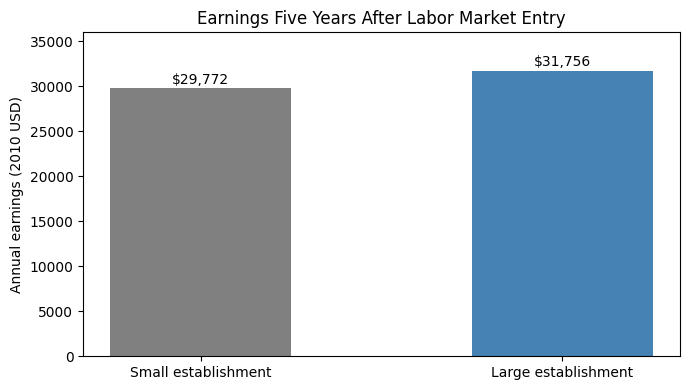

In [39]:
# Mean earnings by initial establishment size

means = final.groupby("large")["real_earnings"].mean()

plt.figure(figsize=(7, 4))

plt.bar(["Small establishment", "Large establishment"], means.values, color=["gray", "steelblue"], width=0.5)

for i, value in enumerate(means.values):
    plt.text(i, value + 500, f"${value:,.0f}", ha="center")

plt.ylabel("Annual earnings (2010 USD)")
plt.title("Earnings Five Years After Labor Market Entry")
plt.ylim(0, 36000)
plt.tight_layout()

plt.savefig("figure1_earnings.png", dpi=300)
plt.show()

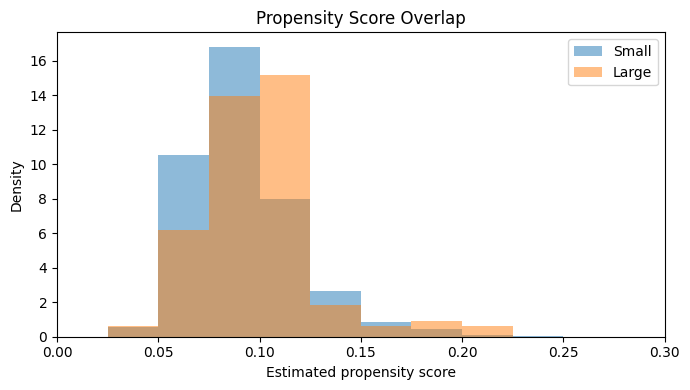

In [41]:
# Preliminary propensity score overlap check

from sklearn.linear_model import LogisticRegression

X = pd.get_dummies(final[control_cols], columns=["race", "start_year"], drop_first=True)

D = final["large"]

model = LogisticRegression(max_iter=5000)
model.fit(X, D)

final["propensity_score"] = model.predict_proba(X)[:, 1]

plt.figure(figsize=(7, 4))

for group, label in [(0, "Small"), (1, "Large")]:
    plt.hist(final.loc[final["large"] == group, "propensity_score"], bins=np.linspace(0, 1, 41), alpha=0.5, density=True, label=label)

plt.xlabel("Estimated propensity score")
plt.ylabel("Density")
plt.title("Propensity Score Overlap")
plt.legend()
plt.xlim(0, 0.30)
plt.tight_layout()

plt.savefig("figure2_overlap.png", dpi=300)
plt.show()

In [42]:
from google.colab import files

files.download("figure1_earnings.png")
files.download("figure2_overlap.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Key EDA finding (one sentence, with a number this notebook printed):**
Workers who started their careers at large establishments earned $1,984 more per year on average five years after entry than those who started at smaller establishments.

**A concern the design will have to handle:**
The treated group is much smaller than the comparison group, and many observations were excluded because of missing information. This may create sample selection bias.

---
## Part 3: Analysis (Milestone 2)

### 3a. The naive estimate

The comparison a client's own analyst would run first. You expect it to be biased; say which way, and why.

In [7]:
# naive = smf.ols("outcome ~ treatment", data=df).fit(cov_type="HC1")
# print(naive.params["treatment"], naive.bse["treatment"])

**Why the naive estimate is biased, and in which direction:** ___

### 3b. The causal estimate

Keep the one cell that matches your design and delete the other three. Each reports the estimate, its standard
error and the diagnostic its design must pass.

In [8]:
# --- DiD: two-way fixed effects, standard errors clustered by the unit that was treated ---
# did = smf.ols("outcome ~ treated_post + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# est, se = did.params["treated_post"], did.bse["treated_post"]
#
# Diagnostic, an event study: one coefficient per period relative to treatment, the period before omitted.
# Pre-period coefficients near zero support parallel trends; they cannot prove it.
# es = smf.ols("outcome ~ C(rel_time, Treatment(reference=-1)) + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# With few treated clusters (under about 20), say so and report a wild cluster bootstrap p-value as well.

In [9]:
# --- IV: two-stage least squares, with the first stage reported ---
# from linearmodels.iv import IV2SLS
# iv = IV2SLS.from_formula("outcome ~ 1 + control_1 + [treatment ~ instrument]", data=df).fit(cov_type="robust")
# est, se = iv.params["treatment"], iv.std_errors["treatment"]
# print(iv.first_stage)          # the first-stage F: below 10 is weak, and the 2SLS interval cannot be trusted
# The estimate is the effect for compliers, the units the instrument moved: say who they are.

In [10]:
# --- RD: local linear, the bandwidth chosen by rdrobust, the effect at the cutoff ---
# from rdrobust import rdrobust
# from rddensity import rddensity
# rd = rdrobust(y=df["outcome"], x=df["running"], c=CUTOFF)
# est, se = rd.coef.loc["Conventional", "Coeff"], rd.se.loc["Conventional", "Std. Err."]
# print(rd)                      # report the bandwidth with the estimate
# print(rd.ci.loc["Robust"])     # the bias-corrected interval: report this one, beside est
# print(rddensity(X=df["running"].to_numpy(), c=CUTOFF).test)   # manipulation at the cutoff
# rdrobust reports right minus left: if treatment is BELOW the cutoff, use running = CUTOFF - x.

In [11]:
# --- DML: partially linear model, cross-fitted, five folds (Topic 24, taught Wed 9 Dec: read Chapter 24 ahead) ---
# from doubleml import DoubleMLData, DoubleMLPLR
# from sklearn.ensemble import RandomForestRegressor
# controls = ["control_1", "control_2", "control_3"]
# dml_data = DoubleMLData(df, y_col="outcome", d_cols="treatment", x_cols=controls)
# learner = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE)
# dml = DoubleMLPLR(dml_data, ml_l=learner, ml_m=learner, n_folds=5)
# dml.fit()
# est, se = dml.coef[0], dml.se[0]
# Diagnostic: overlap. If some units are almost certainly treated or untreated given the controls, the
# estimate leans on extrapolation; plot the cross-fitted treatment predictions by treatment group.

In [12]:
# --- The estimate, its interval and N, in one line the report can quote ---
# ci_low, ci_high = est - 1.96 * se, est + 1.96 * se
# print(f"estimate {est:+.4f} (SE {se:.4f}), 95% CI [{ci_low:+.4f}, {ci_high:+.4f}], N = {len(df):,}")

### 3c. Naive against causal

> The naive estimate is [X]; the causal estimate is [Y]. The gap of [Y - X] is what [the confounder / selection]
> was doing, and its sign matches (or does not match) the direction predicted in 3a.

### 3d. A robustness check that could have overturned the result

The mission asks for at least one check that could have gone the other way. Pick by design:

| Design | A check that can fail |
|---|---|
| DiD | a placebo treatment date in the pre-period; an outcome the policy cannot affect; drop each treated unit in turn |
| IV | a second instrument, alone; the reduced form; an Anderson–Rubin interval if the first stage is weak |
| RD | half and double the bandwidth; a donut that drops the units nearest the cutoff; placebo cutoffs |
| DML | a different learner for the nuisances; a different control set; trimming units with extreme treatment predictions |

For each: what you changed, what you found (the number beside the baseline), and **what it implies** for the claim.

In [13]:
# --- Robustness: your check here ---

### 3e. Sensitivity bound

How strong would an unobserved confounder have to be to erase the estimate, measured against one you observed?
For a regression-based estimate (DiD, DML's final stage, OLS with controls) the **robustness value** answers it
(Cinelli and Hazlett 2020, *JRSS-B* 82(1)). It is the share of the remaining variance of both the treatment and the
outcome that a confounder would have to explain to bring the estimate to zero. Compare it with the strongest control
you have: if no confounder as strong as that control could erase the estimate, say so; if one could, say that.

For RD and IV the equivalent question is about the design's own assumption: how far would the outcome have to jump
at the cutoff for other reasons, or how large a direct effect of the instrument, to explain the estimate?

In [14]:
def robustness_value(t_stat, dof, q=1.0):
    """Cinelli and Hazlett's RV_q: the partial R-squared a confounder needs with BOTH treatment and outcome to
    move the estimate by 100*q percent (q = 1 brings it to zero)."""
    f = q * abs(t_stat) / np.sqrt(dof)
    return 0.5 * (np.sqrt(f**4 + 4 * f**2) - f**2)


def partial_r2(t_stat, dof):
    """A regressor's partial R-squared, recovered from its t-statistic."""
    return t_stat**2 / (t_stat**2 + dof)


# The paper's own example (Darfur, t = 4.18 on 783 degrees of freedom) gives RV = 13.9%:
print(f"check against Cinelli and Hazlett's example: RV = {robustness_value(4.18, 783):.1%} (paper: 13.9%)")

# Your estimate, from a regression with your controls (fit.tvalues / fit.df_resid):
# rv = robustness_value(fit.tvalues["treatment"], fit.df_resid)
# Benchmark: your strongest control's partial R-squared with the outcome, and with the treatment.
# out_fit = smf.ols("outcome ~ treatment + control_1 + control_2", data=df).fit()
# trt_fit = smf.ols("treatment ~ control_1 + control_2", data=df).fit()
# bench_y = partial_r2(out_fit.tvalues["control_1"], out_fit.df_resid)
# bench_d = partial_r2(trt_fit.tvalues["control_1"], trt_fit.df_resid)
# print(f"RV = {rv:.1%}; control_1 explains {bench_y:.1%} of the outcome and {bench_d:.1%} of the treatment")

check against Cinelli and Hazlett's example: RV = 13.9% (paper: 13.9%)


---
## Part 4: Threats to Identification (draft at Milestone 2)

Not "there may be confounding": **which** variable, through **which** path, and **which way** it moves your estimate.
A threat you cannot address is still worth naming. An unnamed one is what the client's analyst will find.

| Threat | Path | Sign of the bias | What I did about it |
|---|---|---|---|
| ___ | ___ → treatment, ___ → outcome | too large / too small / unknown, and why | ___ |
| ___ | ___ | ___ | ___ |
| ___ | ___ | ___ | ___ |

**What I cannot rule out, and what it means for how the client should read the estimate** (an upper bound, a lower
bound, or suggestive only): ___

Milestone 2 asks for at least 500 words across the table and this paragraph.

---
## Part 5: The Streamlit Dashboard

The app must not fit a model. Your deliverable is a causal estimate, a number and a standard error, so write them
to `results.json` here and let the app do arithmetic. The Canvas page **Streamlit Dashboard and Deployment** has
the deployment steps, `requirements.txt`, and every deploy error by its message.

A what-if is an input **the client controls** and an output that is a counterfactual with its interval:
how many units the policy reaches, what it costs, how much hidden bias they are willing to assume. Scaling the
effect beyond the range of treatment in your data is an extrapolation; if your app offers it, the page must say so.

In [15]:
# --- results.json: everything the app needs, printed by this notebook ---
# results = {
#     "question": "Does [treatment] change [outcome]?",
#     "design": "DiD", "estimand": "effect on the treated",
#     "estimate": float(est), "se": float(se), "n": int(len(df)),
#     "unit": "[outcome units] per [treated unit]",
#     "baseline": float(df.loc[df["treatment"] == 0, "outcome"].mean()),   # continuous treatment: df["outcome"].mean()
#     "robustness_value": float(rv),
# }
# with open("results.json", "w") as f:
#     json.dump(results, f, indent=1)
# print(json.dumps(results, indent=1))

In [16]:
app_py = """
import json

import numpy as np
import plotly.graph_objects as go
import streamlit as st

r = json.load(open("results.json"))
st.set_page_config(page_title="Consulting Report", layout="wide")
st.title(r["question"])
st.caption(f"{r['design']}, {r['estimand']}, N = {r['n']:,}")

st.sidebar.header("Your scenario")
reach = st.sidebar.number_input("Units the policy would reach", min_value=1, value=100, step=10)
cost = st.sidebar.number_input("Cost per unit reached", min_value=0.0, value=0.0, step=1.0)
bias = st.sidebar.slider("Hidden bias you are willing to assume (share of the estimate)", -1.0, 1.0, 0.0, 0.05,
                         help="0 trusts the design. 0.5 assumes half the estimate is confounding.")

est = r["estimate"] * (1 - bias)
se = r["se"]
total, total_lo, total_hi = est * reach, (est - 1.96 * se) * reach, (est + 1.96 * se) * reach

c1, c2, c3 = st.columns(3)
c1.metric("Effect per unit", f"{est:+.3f}", help=r["unit"])
c2.metric("Total effect, 95% CI", f"{total:+,.1f}", f"[{total_lo:+,.1f}, {total_hi:+,.1f}]", delta_color="off")
c3.metric("Total cost", f"{cost * reach:,.0f}")

st.markdown(f"If the policy reaches **{reach:,}** units, the estimated total change is **{total:+,.1f}** "
            f"(95% CI {total_lo:+,.1f} to {total_hi:+,.1f}), assuming {bias:.0%} of the estimate is hidden bias.")

grid = np.linspace(-1, 1, 81)
mid = r["estimate"] * (1 - grid)
fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=mid + 1.96 * se, mode="lines", line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=grid, y=mid - 1.96 * se, mode="lines", line=dict(width=0), fill="tonexty",
                         fillcolor="rgba(46,109,180,0.2)", name="95% CI"))
fig.add_trace(go.Scatter(x=grid, y=mid, mode="lines", line=dict(color="#2E6DB4"), name="Effect per unit"))
fig.add_hline(y=0, line_dash="dot", line_color="grey")
fig.add_vline(x=bias, line_dash="dash", line_color="#b03a2e")
fig.update_layout(xaxis_title="Assumed hidden bias (share of the estimate)", yaxis_title=r["unit"],
                  template="plotly_white")
st.plotly_chart(fig)
"""

# Uncomment to write it, then commit app.py, results.json and requirements.txt to your repository:
# with open("app.py", "w") as f:
#     f.write(app_py)
print("app.py template ready: uncomment the two lines above to write it.")

app.py template ready: uncomment the two lines above to write it.


**The `.py` module.** The repository needs a module, not only notebooks. Move the functions you call more than once
(loading and cleaning, the estimate, the robustness check) into `src/analysis.py`, import them here, and let the
README name the one command that reproduces `results.json`.

---
## Part 6: The Five-Minute Video

Exactly three things. Five minutes is a ceiling, not a target.

| | What it is | Yours |
|---|---|---|
| **One visual** | the figure that makes the causal claim believable (Figure 1 or the event study, usually) | ___ |
| **One causal claim** | the estimate, its unit and interval, and the assumption under it, in one sentence | ___ |
| **One recommendation** | what the client should do, and what they should still do at the bottom of the interval | ___ |

### Prepare for the public Q&A

Classmates will open GitHub Issues on your repository. Write your answers to these before they ask:

| They will ask | Your answer |
|---|---|
| "How do you know this is causal?" | ___ |
| "What is the strongest threat, and which way does it bias you?" | ___ |
| "Would this hold for a different population or time?" | ___ |
| "Is the effect big enough to act on?" | ___ |

---
## Part 7: AI Methodology Appendix (P.R.I.M.E.)

At least three entries, each through the five steps: **P**rep, **R**equest, **I**terate, **M**echanism Check,
**E**valuate. Hand it in as a PDF with the report.

### Entry 1: [task]

- **Prep:** what you needed, and what you knew before you asked
- **Request:** the exact prompt
- **Iterate:** what came back, and what you changed or asked again
- **Mechanism Check:** how you verified it: a test you ran, a number you reproduced, a source you checked
- **Evaluate:** what you accepted, what you rejected, and why

### Entry 2: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

### Entry 3: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

> Graded on judgment, not volume. One entry where the model was wrong and you caught it at the Mechanism Check is
> worth more than three where you pasted and moved on.